# Lecture : Graph Transformer

## Lab 05 : Graph Transformer vs. Hierarchical Graph Transformer -- DGL Solution

### Xavier Bresson, Guoji Fu



In [ ]:
# For Google Colaboratory
import sys, os
if 'google.colab' in sys.modules:
    # mount google drive
    from google.colab import drive
    drive.mount('/content/gdrive')
    path_to_file = '/content/gdrive/My Drive/CS5284_2026_codes/07_Graph_Transformers'
    print(path_to_file)
    # change current path to the folder containing "path_to_file"
    os.chdir(path_to_file)
    !pwd
    !pip -q install -f https://data.dgl.ai/wheels/torch-2.6/repo.html dgl==2.5.0 # Install DGL
        

This notebook compares three graph models:

1. GCN (topology only)
2. Graph Transformer + LapPE
3. Hierarchical GT + LapPE

using HEM-style heavy-edge grouping for fixed-size graph coarsening.

The hierarchical SBM size is controlled by only two parameters:

```python
N_HIERARCHIES = 3
N_NODES_PER_COMMUNITY = 10
```

The graph sizes are derived automatically as

$$
N_\ell = q^{H-\ell},
$$

where $H=$ `N_HIERARCHIES` and $q=$ `N_NODES_PER_COMMUNITY`. With the default values, this gives

$$
10^3 \rightarrow 10^2 \rightarrow 10^1
$$
$$
1000 \rightarrow 100 \rightarrow 10
$$

For a 10,000-node original graph and

```python
N_HIERARCHIES = 4
N_NODES_PER_COMMUNITY = 10
```
the notebook would provide $10000\to1000\to100\to10$.


The number of classes stays fixed at 4. Their labels are determined by four different connectivity templates among the final coarse communities : ring, star, two dense modules with a bridge and complete bipartite.

An important aspect of the implementation is that the SBM adjacency, HEM graphs and DGL graphs remain sparse.

### Exercise roadmap

Complete the six marked questions while keeping the supplied data generation,
visualization, DGL batching, training, and evaluation code unchanged.

1. implement heavy-edge grouping and sparse graph coarsening;
2. construct normalized-Laplacian positional encodings;
3. implement edge-sparse multi-head attention; and
4. implement parent pooling and hierarchical forward propagation.

Every answer region is delimited by `YOUR CODE STARTS HERE` and
`YOUR CODE ENDS HERE`.


## Imports


In [2]:
import math
import random
import time
import warnings
import numpy as np
import pandas as pd
import scipy.sparse
import scipy.sparse.linalg
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import networkx as nx

import dgl
import dgl.function as fn
from dgl.nn import GraphConv
from dgl.nn.functional import edge_softmax

print("PyTorch:", torch.__version__)
print("DGL:", dgl.__version__)

# reproduce result
torch.set_num_threads(1)
def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed(0)


PyTorch: 2.6.0+cpu
DGL: 2.5.0


## A 4-class hierarchical SBM dataset

This cell defines the size of the hierarchy, the within-hierarchy edge probabilities and weights, and the four class-specific coarse connectivity templates.

Let

- $H=$ `N_HIERARCHIES` be the number of graph resolutions,
- $q=$ `N_NODES_PER_COMMUNITY` be the branching / group size,
- $L=H-1=$ `HIERARCHY_LEVELS` be the number of coarsening transitions.

The number of nodes at hierarchy level $\ell$ is

$$
N^{(\ell)} = q^{H-\ell},
\qquad \ell=0,\ldots,H-1,
$$

so, for example, $H=3,\ q=10$ gives $1000\to100\to10$.

The community sizes are

$$
s_\ell=q^{\ell+1},
\qquad \ell=0,\ldots,L-1.
$$

For $L>1$, `np.geomspace` makes the within-hierarchy probabilities and weights vary geometrically from the fine to the mesoscopic endpoint :

$$
p_\ell
=
P_{\mathrm{fine}}
\left(\frac{P_{\mathrm{meso}}}{P_{\mathrm{fine}}}\right)^{\ell/(L-1)},
\qquad
w_\ell
=
W_{\mathrm{fine}}
\left(\frac{W_{\mathrm{meso}}}{W_{\mathrm{fine}}}\right)^{\ell/(L-1)}.
$$

Thus fine communities are denser and have stronger edges, while coarser planted communities are progressively sparser and weaker. The four graph labels are defined by different connectivity templates among the final $q$ coarse communities.


N_HIERARCHIES: 3
N_NODES_PER_COMMUNITY: 10
number of nodes at the original resolution: 1000
derived hierarchy sizes: [1000, 100, 10]
within-level community sizes: [10, 100]
within-level probabilities: [1.0, 0.07999999821186066]
within-level weights: [10.0, 3.0]
class 0 (ring): 10 final coarse nodes, 10 high-probability coarse relations
class 1 (star): 10 final coarse nodes, 9 high-probability coarse relations
class 2 (two dense modules (5+5)): 10 final coarse nodes, 21 high-probability coarse relations
class 3 (5x5 bipartite): 10 final coarse nodes, 25 high-probability coarse relations



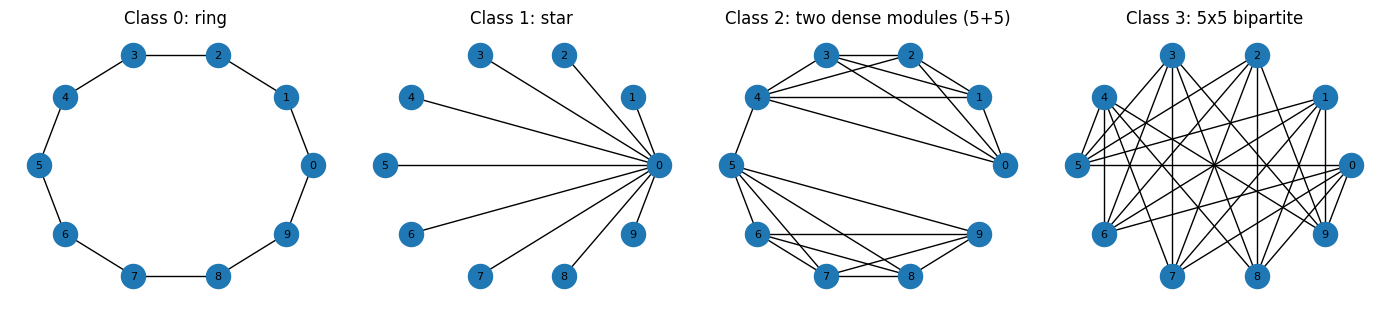

In [3]:
# Two controls determine the complete hierarchy size
# Example: H=3, q=10 -> [10^3, 10^2, 10^1] = [1000, 100, 10].
N_HIERARCHIES = 3
N_NODES_PER_COMMUNITY = 10
N_CLASSES = 4

# Validate hierarchy controls before deriving graph sizes.
if not isinstance(N_HIERARCHIES, int) or N_HIERARCHIES < 2:
    raise ValueError("N_HIERARCHIES must be an integer >= 2 for hierarchical pooling.")
if not isinstance(N_NODES_PER_COMMUNITY, int) or N_NODES_PER_COMMUNITY < 2:
    raise ValueError("N_NODES_PER_COMMUNITY must be an integer >= 2.")

GROUP_SIZE = N_NODES_PER_COMMUNITY
HIERARCHY_LEVELS = N_HIERARCHIES - 1  # number of HEM/coarsening transitions
HIERARCHY_SIZES = [ N_NODES_PER_COMMUNITY ** power for power in range(N_HIERARCHIES, 0, -1) ]
N_NODES = HIERARCHY_SIZES[0]
N_TOP_COMMUNITIES = HIERARCHY_SIZES[-1] # = N_NODES_PER_COMMUNITY
TOP_COMMUNITY_SIZE = N_NODES // N_TOP_COMMUNITIES

# Original-node community sizes represented by the nested levels
# Default is H=3, q=10 -> [10, 100]
PLANTED_COMMUNITY_SIZES = [ N_NODES_PER_COMMUNITY ** power for power in range(1, N_HIERARCHIES) ]

# Number of training and test graphs
N_TRAIN_PER_CLASS = 100
# N_TRAIN_PER_CLASS = 2 # debug
N_TEST_PER_CLASS = 10
DATASET_SEEDS = list(range(1000, 1000 + N_TRAIN_PER_CLASS + N_TEST_PER_CLASS))

# Endpoints for within-hierarchy probabilities
# For H=3 these give exactly [P_FINE, P_MESO] = [1.00, 0.08]
P_FINE = 1.00
P_MESO = 0.08
P_MACRO_HIGH = 0.020
P_MACRO_LOW = 0.0002

# Endpoints for within-hierarchy edge weights
# For H=3 these give exactly [W_FINE, W_MESO] = [10, 3]
W_FINE = 10.0
W_MESO = 3.0
W_MACRO = 1.0
if HIERARCHY_LEVELS == 1:
    INTRA_LEVEL_PROBABILITIES = np.array([P_FINE], dtype=np.float32)
    INTRA_LEVEL_WEIGHTS = np.array([W_FINE], dtype=np.float32)
else:
    INTRA_LEVEL_PROBABILITIES = np.geomspace(P_FINE, P_MESO, num=HIERARCHY_LEVELS).astype(np.float32)
    INTRA_LEVEL_WEIGHTS = np.geomspace(W_FINE, W_MESO, num=HIERARCHY_LEVELS).astype(np.float32)

# Four class templates on the final n_coarse communities
def make_macro_templates(n_coarse):
    left = n_coarse // 2
    right = n_coarse - left
    ring = nx.cycle_graph(n_coarse)
    star = nx.star_graph(n_coarse - 1)
    two_modules = nx.disjoint_union(nx.complete_graph(left), nx.complete_graph(right))
    two_modules.add_edge(left - 1, left)
    bipartite = nx.complete_bipartite_graph(left, right)
    names = ["ring", "star", f"two dense modules ({left}+{right})", f"{left}x{right} bipartite"]
    return [ring, star, two_modules, bipartite], names

MACRO_TEMPLATES, MACRO_TEMPLATE_NAMES = make_macro_templates(N_TOP_COMMUNITIES)

# Stack the four macro-template graphs into class-indexed adjacency matrices
MACRO_ADJ = np.stack([nx.to_numpy_array(G, nodelist=range(N_TOP_COMMUNITIES), dtype=np.float32) for G in MACRO_TEMPLATES])

# Print stats
print("N_HIERARCHIES:", N_HIERARCHIES)
print("N_NODES_PER_COMMUNITY:", N_NODES_PER_COMMUNITY)
print("number of nodes at the original resolution:", N_NODES_PER_COMMUNITY**N_HIERARCHIES)
print("derived hierarchy sizes:", HIERARCHY_SIZES)
print("within-level community sizes:", PLANTED_COMMUNITY_SIZES)
print("within-level probabilities:", INTRA_LEVEL_PROBABILITIES.tolist())
print("within-level weights:", INTRA_LEVEL_WEIGHTS.tolist())
for label, (name, G) in enumerate(zip(MACRO_TEMPLATE_NAMES, MACRO_TEMPLATES)):
    print(f"class {label} ({name}): {G.number_of_nodes()} final coarse nodes, {G.number_of_edges()} high-probability coarse relations")

# Plot the 4 classes
print('')
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for label, (ax, G) in enumerate(zip(axes, MACRO_TEMPLATES)):
    pos = nx.circular_layout(G)
    nx.draw_networkx(G, pos=pos, ax=ax, node_size=300, font_size=8, with_labels=True)
    ax.set_title(f"Class {label}: {MACRO_TEMPLATE_NAMES[label]}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## Sampling one hierarchical SBM graph

The next cell samples a weighted hierarchical stochastic block model (SBM) directly into a sparse adjacency matrix. Nodes are ordered so that every community occupies a contiguous block, which lets the sampler work one block at a time without constructing a dense $N\times N$ matrix.

For two disjoint blocks of sizes $s_a$ and $s_b$, the number of possible edges is

$$
M_{\mathrm{between}}=s_a s_b,
$$

while inside one block of size $s$,

$$
M_{\mathrm{within}}=\binom{s}{2}=\frac{s(s-1)}{2}.
$$

For a block with connection probability $p$, the sampler first draws the number of edges

$$
E\sim\mathrm{Binomial}(M,p),
$$

and then selects $E$ unique node pairs. At level $\ell$, sampled edges receive weight $w_\ell$.

For the final coarse communities $a,b$, the class template chooses the macro connection probability:

$$
p_{ab}^{\mathrm{macro}}
=
\begin{cases}
P_{\mathrm{macro\_high}}\ & M^{(y)}_{ab}=1,\\
P_{\mathrm{macro\_low}}\ & M^{(y)}_{ab}=0,
\end{cases}
$$

where $M^{(y)}$ is the macro adjacency template for class $y$. The final sparse adjacency is made symmetric, $A_{ij}=A_{ji}$, and each node receives normalized binary degree :

$$
x_i=\frac{d_i}{N-1},
\qquad
d_i=\sum_j \mathbf{1}[A_{ij}>0].
$$


In [4]:
# Sample unique edges between two disjoint contiguous node blocks
def _sample_bipartite_block(rng, start_a, size_a, start_b, size_b, probability):
    n_possible = int(size_a) * int(size_b)
    if n_possible == 0 or probability <= 0.0:
        empty = np.empty(0, dtype=np.int64)
        return empty, empty
    if probability >= 1.0:
        flat = np.arange(n_possible, dtype=np.int64)
    else:
        n_edges = int(rng.binomial(n_possible, probability))
        if n_edges == 0:
            empty = np.empty(0, dtype=np.int64)
            return empty, empty
        flat = rng.choice(n_possible, size=n_edges, replace=False)
    u = start_a + flat // size_b
    v = start_b + flat % size_b
    return u.astype(np.int64, copy=False), v.astype(np.int64, copy=False)

# Sample unique undirected pairs inside one small contiguous block
def _sample_within_block(rng, start, size, probability):
    iu, iv = np.triu_indices(size, k=1)
    n_possible = len(iu)
    if probability >= 1.0:
        chosen = np.arange(n_possible, dtype=np.int64)
    elif probability <= 0.0:
        empty = np.empty(0, dtype=np.int64)
        return empty, empty
    else:
        n_edges = int(rng.binomial(n_possible, probability))
        if n_edges == 0:
            empty = np.empty(0, dtype=np.int64)
            return empty, empty
        chosen = rng.choice(n_possible, size=n_edges, replace=False)
    return ( (start + iu[chosen]).astype(np.int64, copy=False), (start + iv[chosen]).astype(np.int64, copy=False), )

# Sample one weighted hierarchical SBM directly as a sparse CSR matrix
def make_hierarchical_sbm(label, seed):
    rng = np.random.default_rng(seed + 100_000 * int(label))
    u_parts = []
    v_parts = []
    w_parts = []
    # Nested planted levels. Level 0 samples within q-node communities.
    # Higher levels sample between distinct immediate child communities only.
    for level, (community_size, p_level, w_level) in enumerate(zip( PLANTED_COMMUNITY_SIZES, INTRA_LEVEL_PROBABILITIES, INTRA_LEVEL_WEIGHTS, )):
        community_size = int(community_size)
        p_level = float(p_level)
        w_level = float(w_level)
        if level == 0:
            for start in range(0, N_NODES, community_size):
                u, v = _sample_within_block( rng, start, community_size, p_level )
                if len(u):
                    u_parts.append(u)
                    v_parts.append(v)
                    w_parts.append(np.full(len(u), w_level, dtype=np.float32))
        else:
            child_size = community_size // N_NODES_PER_COMMUNITY
            for parent_start in range(0, N_NODES, community_size):
                for child_a in range(N_NODES_PER_COMMUNITY):
                    start_a = parent_start + child_a * child_size
                    for child_b in range(child_a + 1, N_NODES_PER_COMMUNITY):
                        start_b = parent_start + child_b * child_size
                        u, v = _sample_bipartite_block( rng, start_a, child_size, start_b, child_size, p_level, )
                        if len(u):
                            u_parts.append(u)
                            v_parts.append(v)
                            w_parts.append( np.full(len(u), w_level, dtype=np.float32) )
    # Macro edges between final coarse communities
    for coarse_a in range(N_TOP_COMMUNITIES):
        start_a = coarse_a * TOP_COMMUNITY_SIZE
        for coarse_b in range(coarse_a + 1, N_TOP_COMMUNITIES):
            start_b = coarse_b * TOP_COMMUNITY_SIZE
            p_macro = ( P_MACRO_HIGH if MACRO_ADJ[label, coarse_a, coarse_b] > 0 else P_MACRO_LOW )
            u, v = _sample_bipartite_block( rng, start_a, TOP_COMMUNITY_SIZE, start_b, TOP_COMMUNITY_SIZE, float(p_macro), )
            if len(u):
                u_parts.append(u)
                v_parts.append(v)
                w_parts.append(np.full(len(u), W_MACRO, dtype=np.float32))
    if not u_parts:
        A = scipy.sparse.csr_matrix((N_NODES, N_NODES), dtype=np.float32)
    else:
        u = np.concatenate(u_parts)
        v = np.concatenate(v_parts)
        w = np.concatenate(w_parts)
        rows = np.concatenate([u, v])
        cols = np.concatenate([v, u])
        data = np.concatenate([w, w])
        A = scipy.sparse.csr_matrix( (data, (rows, cols)), shape=(N_NODES, N_NODES), dtype=np.float32, )
        A.sum_duplicates()
        A.eliminate_zeros()
        A.sort_indices()
    binary_degree = np.diff(A.indptr).reshape(-1, 1).astype(np.float32)
    x = binary_degree / float(max(N_NODES - 1, 1))
    return A, x, int(label)


A_demo, x_demo, y_demo = make_hierarchical_sbm( label=0, seed=DATASET_SEEDS[0] )
print("demo shape:", A_demo.shape, "label:", y_demo)
print("undirected edges:", A_demo.nnz // 2)
print("unique positive weights:", np.unique(A_demo.data))
print( "sparse adjacency storage (MB):", round((A_demo.data.nbytes + A_demo.indices.nbytes + A_demo.indptr.nbytes) / 1e6, 2), )


demo shape: (1000, 1000) label: 0
undirected edges: 10138
unique positive weights: [ 1.  3. 10.]
sparse adjacency storage (MB): 0.17


## HEM-style heavy-edge grouping at any hierarchy depth

The next cell builds the graph hierarchy using a greedy heavy-edge grouping rule. Instead of ordinary pairwise Heavy-Edge Matching (each parent has two children), here each parent contains exactly `GROUP_SIZE = N_NODES_PER_COMMUNITY` children.

If $G$ is the current partially formed group, each unassigned candidate node $v$ receives the heavy-edge score

$$
s(v\mid G)=\sum_{u\in G} W_{uv},
$$

and the next node is chosen by

$$
v^\star=\arg\max_{v\ \mathrm{unassigned}} s(v\mid G).
$$

The parent map $p(i)$ is represented by an assignment matrix $P$,

$$
P_{ir}=
\begin{cases}
1, & p(i)=r,\\
0, & \text{otherwise}.
\end{cases}
$$

For local processing, edges between different HEM groups are removed:

$$
D^{(\ell)}_{ij}
=
A^{(\ell)}_{ij}\,
\mathbf{1}[p(i)=p(j)],
\qquad i\ne j.
$$

The full graph is then coarsened by summing edge weights between parent groups,

$$
A^{(\ell+1)}=P^\top A^{(\ell)}P,
$$

with diagonal entries removed afterward. Because each parent has $q$ children,

$$
N^{(\ell+1)}=\frac{N^{(\ell)}}{q}.
$$

### Exercise 1 — Heavy-edge grouping and sparse coarsening

#### Question 1.1: Select one fixed-size heavy-edge group

For the current partial group, compute every unassigned candidate's total
incident weight to the group. Select the first maximizer, with the supplied
deterministic fallback when no positive connection remains.

#### Question 1.2: Build the parent assignment and coarsened adjacency

Construct the sparse assignment matrix $P$ from the parent map, then compute
$P^\top W P$ and remove its diagonal.


In [5]:
# Greedy HEM-style grouping into fixed-size communities
def heavy_edge_grouping_parent_map(W, group_size=GROUP_SIZE):
    W = scipy.sparse.csr_matrix(W)
    n = W.shape[0]
    if n % group_size != 0:
        raise ValueError(f"{n} nodes cannot be divided into groups of {group_size}.")
    unassigned = np.ones(n, dtype=bool)
    parent = np.full(n, -1, dtype=np.int64)
    parent_id = 0
    while unassigned.any():
        seed = int(np.flatnonzero(unassigned)[0])
        group = [seed]
        unassigned[seed] = False
        while len(group) < group_size:
            candidates = np.flatnonzero(unassigned)
            # Heavy-edge score = total edge weight from the candidate to the current group.
            ###############################################
            # YOUR CODE STARTS HERE
            # YOUR CODE
            ###############################################
            scores = np.asarray(W[group][:, candidates].sum(axis=0)).ravel()
            best_score = scores.max(initial=0.0)
            if best_score <= 0:
                # Deterministic fallback for a disconnected remainder.
                chosen = int(candidates[0])
            else:
                best = np.flatnonzero(np.isclose(scores, best_score, rtol=1e-10, atol=1e-12))
                chosen = int(candidates[best[0]])
            ###############################################
            # YOUR CODE ENDS HERE
            ###############################################
            group.append(chosen)
            unassigned[chosen] = False
        parent[np.asarray(group, dtype=np.int64)] = parent_id
        parent_id += 1
    return parent

# Return W as CSR with all diagonal entries removed, without CSR setdiag()
def sparse_without_diagonal(W):
    coo = scipy.sparse.coo_matrix(W)
    keep = coo.row != coo.col
    out = scipy.sparse.csr_matrix( (coo.data[keep], (coo.row[keep], coo.col[keep])), shape=coo.shape, )
    out.eliminate_zeros()
    out.sum_duplicates()
    out.sort_indices()
    return out

# Keep only edges whose endpoints belong to the same heavy-edge group
def disconnect_between_hem_groups(W, parent):
    coo = scipy.sparse.coo_matrix(W)
    keep = (parent[coo.row] == parent[coo.col]) & (coo.row != coo.col)
    local = scipy.sparse.csr_matrix( (coo.data[keep], (coo.row[keep], coo.col[keep])), shape=coo.shape, )
    local.eliminate_zeros()
    local.sum_duplicates()
    local.sort_indices()
    return local

# Return sparse CSR full graphs, parent maps, and sparse local graphs
def hem_hierarchy(A, levels=HIERARCHY_LEVELS, group_size=GROUP_SIZE):
    W = sparse_without_diagonal(A)
    graphs = [W.copy()]
    parents = []
    local_graphs = []
    for _ in range(levels):
        n = W.shape[0]
        parent = heavy_edge_grouping_parent_map(W, group_size=group_size)
        local_graph = disconnect_between_hem_groups(W, parent)
        n_parent = n // group_size
        ###############################################
        # YOUR CODE STARTS HERE
        # YOUR CODE
        ###############################################
        P = scipy.sparse.csr_matrix( (np.ones(n, dtype=np.float32), (np.arange(n), parent)), shape=(n, n_parent), )
        W_next = sparse_without_diagonal(P.T @ W @ P)
        ###############################################
        # YOUR CODE ENDS HERE
        ###############################################
        parents.append(parent)
        local_graphs.append(local_graph)
        graphs.append(W_next)
        W = W_next
    return graphs, parents, local_graphs


graphs_demo, parents_demo, local_graphs_demo = hem_hierarchy(A_demo)
print("HEM-style hierarchy sizes:", [g.shape[0] for g in graphs_demo])
print("children per parent:", [np.unique(np.bincount(p)).tolist() for p in parents_demo])


HEM-style hierarchy sizes: [1000, 100, 10]
children per parent: [[10], [10]]


## Two graph sequences are used after HEM

At every non-final hierarchy level, we keep two related graph objects:

1. **Full / coarsened graphs** $A^{(0)},A^{(1)},\ldots,A^{(H-1)}$, used for HEM grouping and coarsening.
2. **Disconnected local graphs** $D^{(0)},D^{(1)},\ldots,D^{(H-2)}$, used by the hierarchical GT stages.

For each parent map $p^{(\ell)}$, the pooling matrix $P^{(\ell)}$ produces

$$
A^{(\ell+1)}
=
(P^{(\ell)})^T
A^{(\ell)}
P^{(\ell)}.
$$

The local graph keeps only edges whose endpoints share the same HEM parent:

$$
D_{ij}^{(\ell)}
=
\begin{cases}
A_{ij}^{(\ell)}, & p_i^{(\ell)}=p_j^{(\ell)},\\
0, & p_i^{(\ell)}\neq p_j^{(\ell)}.
\end{cases}
$$


## Visualize the four classes across all hierarchy levels

For presentation, one graph from each class is coarsened using the same sparse HEM routine used by the model.



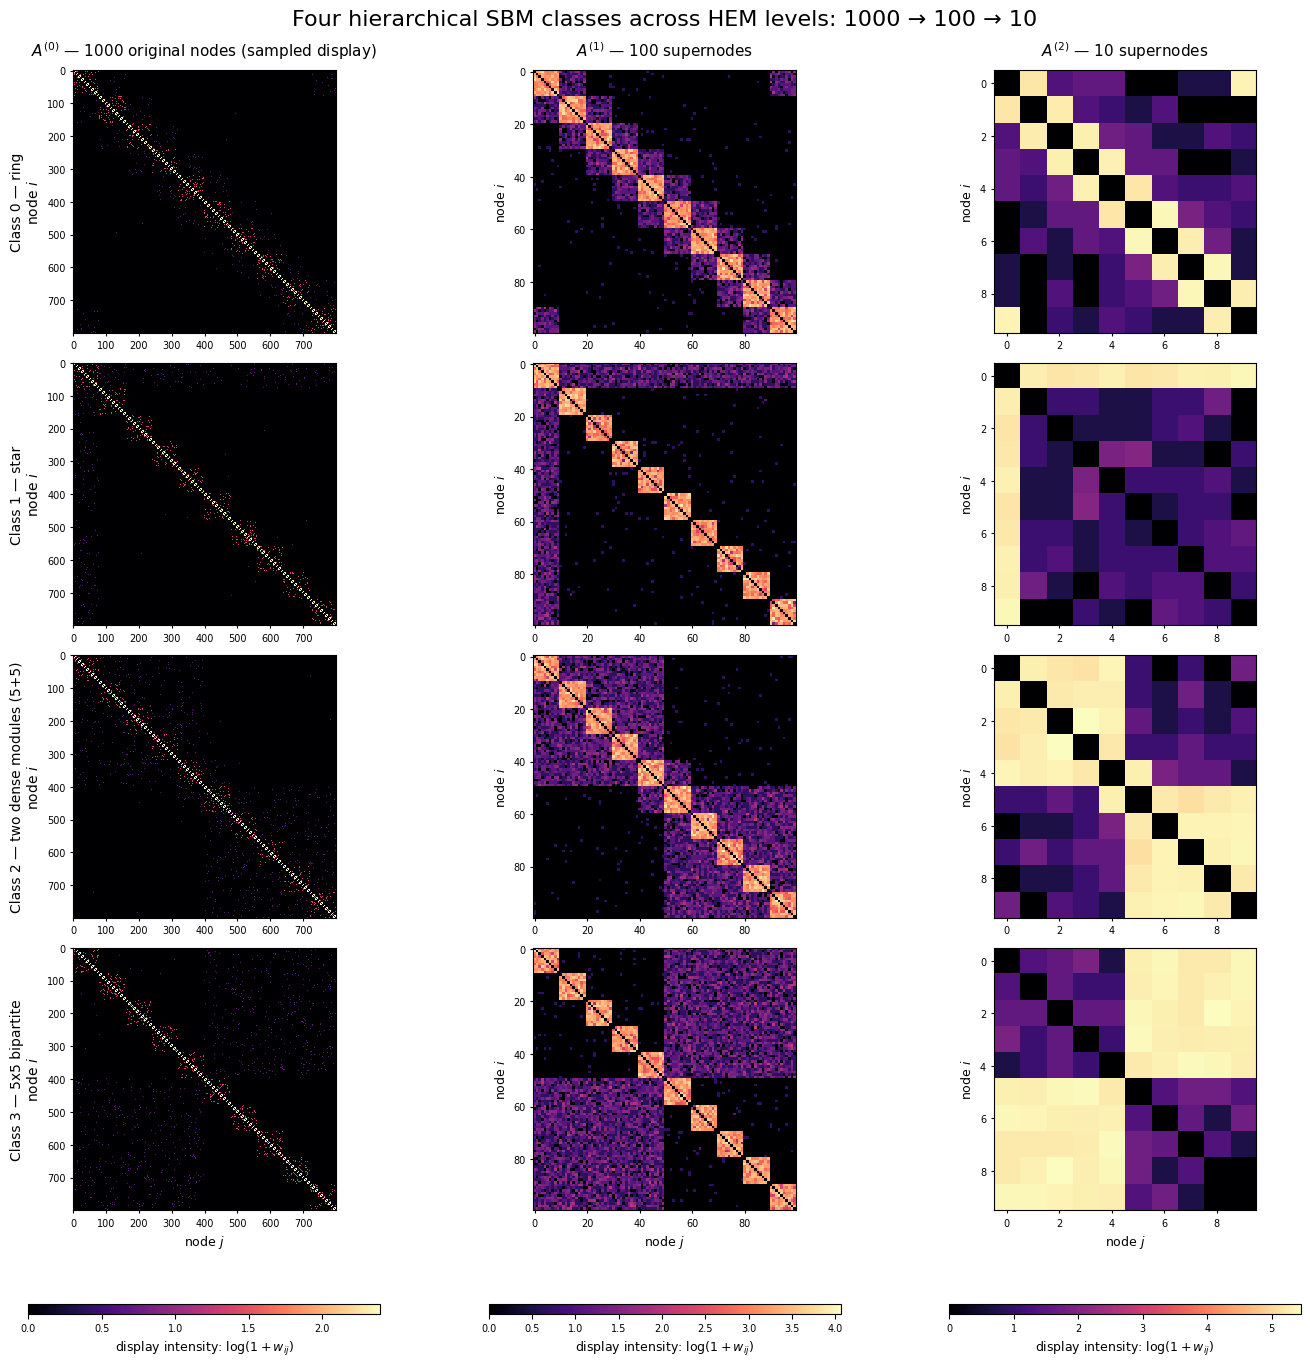

In [6]:
MAX_HIERARCHY_VIS_NODES = 2000
MAX_ADJ_DISPLAY_NODES = 800
VIS_SEED = DATASET_SEEDS[0]
VIS_EXAMPLES = []

# Build four-class hierarchy visualizations only when the original graph is small enough to display safely
if N_NODES > MAX_HIERARCHY_VIS_NODES:
    print( f"Skipping four-class hierarchy visualization because N_NODES={N_NODES:,} " f"> {MAX_HIERARCHY_VIS_NODES:,}. The training graphs remain sparse." )
else:
    for label in range(N_CLASSES):
        A0, _, _ = make_hierarchical_sbm(label=label, seed=VIS_SEED)
        graphs, parents, _ = hem_hierarchy(A0)
        VIS_EXAMPLES.append({ "label": label, "name": MACRO_TEMPLATE_NAMES[label], "graphs": graphs, "parents": parents, })
    level_sizes = HIERARCHY_SIZES
    level_labels = [rf"$A^{{({level})}}$" for level in range(N_HIERARCHIES)]
    def sparse_display_array(W, max_nodes=MAX_ADJ_DISPLAY_NODES):
        n = W.shape[0]
        if n <= max_nodes:
            idx = np.arange(n)
        else:
            idx = np.linspace(0, n - 1, max_nodes, dtype=np.int64)
        return W[idx][:, idx].toarray()
    column_vmax = []
    for level in range(N_HIERARCHIES):
        vmax = max( float(np.log1p(ex["graphs"][level].data).max(initial=0.0)) for ex in VIS_EXAMPLES )
        column_vmax.append(vmax)
    fig, axes = plt.subplots( N_CLASSES, N_HIERARCHIES, figsize=(4.6 * N_HIERARCHIES, 3.3 * N_CLASSES), constrained_layout=True, squeeze=False, )
    column_images = [None] * N_HIERARCHIES
    for row, ex in enumerate(VIS_EXAMPLES):
        for col, (n_level, level_label) in enumerate(zip(level_sizes, level_labels)):
            ax = axes[row, col]
            shown = np.log1p(sparse_display_array(ex["graphs"][col]))
            im = ax.imshow( shown, cmap="magma", vmin=0.0, vmax=column_vmax[col], interpolation="nearest", aspect="equal", rasterized=True, )
            column_images[col] = im
            if row == 0:
                kind = "original nodes" if col == 0 else "supernodes"
                suffix = "" if n_level <= MAX_ADJ_DISPLAY_NODES else " (sampled display)"
                ax.set_title( f"{level_label} — {n_level} {kind}{suffix}", fontsize=11, pad=10 )
            if col == 0:
                ax.set_ylabel(f"Class {ex['label']} — {ex['name']}\nnode $i$", fontsize=10)
            else:
                ax.set_ylabel("node $i$", fontsize=9)
            if row == N_CLASSES - 1:
                ax.set_xlabel("node $j$", fontsize=9)
            ax.tick_params(labelsize=7, length=2)
    for col in range(N_HIERARCHIES):
        cbar = fig.colorbar( column_images[col], ax=axes[:, col], location="bottom", shrink=0.78, pad=0.04, aspect=35, )
        cbar.set_label(r"display intensity: $\log(1+w_{ij})$", fontsize=9)
        cbar.ax.tick_params(labelsize=7)
    hierarchy_text = " → ".join(map(str, HIERARCHY_SIZES))
    fig.suptitle( f"Four hierarchical SBM classes across HEM levels: {hierarchy_text}", fontsize=16, y=1.02, )
    plt.show()


### Interactive 3D HEM hierarchy


In [7]:
# Interactive 3D HEM hierarchy for the same four examples shown above.
# The level-0 layout is computed once per class; all coarser positions are
# centroids of the original-node positions, so the hierarchy stays spatially aligned.

# Map every original node to its cluster at each hierarchy level
def hierarchy_memberships(n0, parents):
    memberships = [np.arange(n0, dtype=np.int64)]
    node_to_cluster = np.arange(n0, dtype=np.int64)
    for parent in parents:
        node_to_cluster = parent[node_to_cluster]
        memberships.append(node_to_cluster.copy())
    return memberships

# Place each supernode at the centroid of its original member nodes
def aggregate_positions_3d(positions, memberships, n_clusters):
    out = np.zeros((n_clusters, 3), dtype=np.float64)
    counts = np.zeros(n_clusters, dtype=np.float64)
    for original_node, cluster_id in enumerate(memberships):
        out[cluster_id] += positions[original_node]
        counts[cluster_id] += 1.0
    out /= counts[:, None]
    return {cluster_id: out[cluster_id] for cluster_id in range(n_clusters)}

# Color each node/supernode by the final HEM cluster containing it
def final_cluster_colors(memberships_at_level, final_memberships, n_clusters):
    colors = np.zeros(n_clusters, dtype=int)
    for cluster_id in range(n_clusters):
        original_nodes = np.where(memberships_at_level == cluster_id)[0]
        final_ids = np.unique(final_memberships[original_nodes])
        assert len(final_ids) == 1
        colors[cluster_id] = final_ids[0]
    return colors

# Convert a sparse weighted adjacency matrix to NetworkX without self-loops
def graph_without_diagonal(W):
    return nx.from_scipy_sparse_array(sparse_without_diagonal(W))

# Convert graph edges into a Plotly 3D line trace using the supplied node positions.
def edge_trace_3d(G, pos, width=3.0):
    x_edges, y_edges, z_edges = [], [], []
    for u, v in G.edges():
        x0, y0, z0 = pos[u]
        x1, y1, z1 = pos[v]
        x_edges.extend([x0, x1, None])
        y_edges.extend([y0, y1, None])
        z_edges.extend([z0, z1, None])
    return go.Scatter3d( x=x_edges, y=y_edges, z=z_edges, mode="lines", line=dict(width=width, color="rgba(70,70,70,0.60)"), hoverinfo="skip", showlegend=False, )

# Create a Plotly 3D node trace with cluster-aware colors, sizes, and hover labels.
def node_trace_3d(pos, node_colors, cluster_sizes, level, class_label):
    nodes = sorted(pos.keys())
    xyz = np.array([pos[node] for node in nodes])
    sizes = 4 + 2.2 * np.sqrt(cluster_sizes[nodes])
    hover_text = [ f"class: {class_label}<br>level: {level}<br>node / supernode: {node}<br>" f"original nodes represented: {int(cluster_sizes[node])}<br>" f"final HEM cluster: {int(node_colors[node])}" for node in nodes ]
    return go.Scatter3d( x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2], mode="markers", marker=dict( size=sizes, color=node_colors[nodes], colorscale="Turbo", cmin=0, cmax=HIERARCHY_SIZES[-1] - 1, opacity=0.95, line=dict(width=0.6, color="black"), showscale=False, ), text=hover_text, hovertemplate="%{text}<extra></extra>", showlegend=False, )

N_LEVELS_VIS = N_HIERARCHIES

# Build one subplot title for every class and hierarchy level
subplot_titles = []
for ex in VIS_EXAMPLES:
    for level, n_level in enumerate(HIERARCHY_SIZES):
        kind = "original nodes" if level == 0 else "HEM supernodes"
        title = f"Class {ex['label']} — {ex['name']}<br>Level {level}: {n_level} {kind}"
        # if level == N_LEVELS_VIS - 1:
        #     title = f"<b>{title}</b>"
        subplot_titles.append(title)

fig3d = make_subplots( rows=N_CLASSES, cols=N_LEVELS_VIS, specs=[[{"type": "scene"}] * N_LEVELS_VIS for _ in range(N_CLASSES)], subplot_titles=subplot_titles, column_widths=[1.0] * N_LEVELS_VIS, horizontal_spacing=0.015, vertical_spacing=0.045, )

# Render every class across all hierarchy levels using aligned 3D layouts and record node counts
level_node_counts = []
for row, ex in enumerate(VIS_EXAMPLES, start=1):
    graphs_vis = ex["graphs"]
    parents_vis = ex["parents"]
    A0_binary = graphs_vis[0].copy().tocsr()
    A0_binary.data = np.ones_like(A0_binary.data)
    G0_layout = graph_without_diagonal(A0_binary)
    pos0 = nx.spring_layout(G0_layout, seed=3, dim=3)
    memberships = hierarchy_memberships(graphs_vis[0].shape[0], parents_vis)
    assert len(memberships) == len(graphs_vis) == N_LEVELS_VIS
    row_counts = []
    for level in range(N_LEVELS_VIS):
        G_level = graph_without_diagonal(graphs_vis[level])
        pos_level = ( pos0 if level == 0 else aggregate_positions_3d( pos0, memberships[level], graphs_vis[level].shape[0], ) )
        n_clusters = graphs_vis[level].shape[0]
        row_counts.append(n_clusters)
        cluster_sizes = np.bincount(memberships[level], minlength=n_clusters)
        node_colors = final_cluster_colors( memberships[level], memberships[-1], n_clusters )
        if N_LEVELS_VIS == 1:
            edge_width = 3.0
        else:
            edge_width = 1.2 + 3.8 * level / (N_LEVELS_VIS - 1)
        fig3d.add_trace( edge_trace_3d(G_level, pos_level, width=edge_width), row=row, col=level + 1, )
        fig3d.add_trace( node_trace_3d( pos_level, node_colors, cluster_sizes, level, ex["label"], ), row=row, col=level + 1, )
    level_node_counts.append(row_counts)

scene_style = dict( xaxis=dict(showgrid=True, showticklabels=False, title="", zeroline=False), yaxis=dict(showgrid=True, showticklabels=False, title="", zeroline=False), zaxis=dict(showgrid=True, showticklabels=False, title="", zeroline=False), aspectmode="data", camera=dict(eye=dict(x=1.35, y=1.35, z=1.05)), )

n_scenes = N_CLASSES * N_LEVELS_VIS
for scene_id in range(1, n_scenes + 1):
    scene_name = "scene" if scene_id == 1 else f"scene{scene_id}"
    fig3d.layout[scene_name].update(scene_style)

fig3d.update_layout( autosize=True, height=420 * N_CLASSES + 100, margin=dict(l=0, r=0, b=0, t=115, pad=0), title=dict( text="Interactive 3D HEM hierarchy — drag to rotate, scroll to zoom", x=0.5, xanchor="center", font=dict(size=20), ), showlegend=False, )

fig3d.show(config=dict(scrollZoom=True, displaylogo=False, responsive=True))


Output hidden; open in https://colab.research.google.com to view.

## Laplacian positional encoding (LapPE)

We use the first non-trivial eigenvectors of the normalized weighted graph Laplacian. LapPE is computed once per graph at the original resolution `N_NODES` and will be shared by the flat and hierarchical Transformer inputs.

Because a dense eigendecomposition would be expensive for larger choices of `N_NODES`, the notebook uses SciPy's sparse `eigsh` routine to compute only the few eigenvectors needed.

### Mathematical definition of LapPE

LapPE is computed from the original weighted adjacency matrix

$$
A^{(0)}\in\mathbb{R}^{N\times N},
\qquad N=\texttt{N\_NODES}.
$$

Define the weighted degree matrix

$$
D^{(0)}_{ii}=\sum_j A^{(0)}_{ij}.
$$

The normalized weighted graph Laplacian is

$$
L^{(0)}
=
I-
\left(D^{(0)}\right)^{-1/2}
A^{(0)}
\left(D^{(0)}\right)^{-1/2}.
$$

If

$$
L^{(0)}u_k=\lambda_k u_k,
\qquad
0\le\lambda_0\le\lambda_1\le\lambda_2\le\cdots\le 2,
$$

then the notebook discards the smallest-eigenvalue eigenvector and uses the next `POS_ENC_DIM = 8` vectors:

$$
\mathrm{LapPE}^{(0)}
=
\begin{bmatrix}u_1&u_2&\cdots&u_8\end{bmatrix}
\in\mathbb{R}^{N\times8}.
$$

The same original-resolution LapPE is used by both Transformer models.

### Exercise 2 — Normalized-Laplacian positional encoding

#### Question 2.1: Compute the first non-trivial Laplacian eigenvectors

Construct $D^{-1/2}$ and $L=I-D^{-1/2}WD^{-1/2}$, use sparse `eigsh` to
obtain the smallest eigenpairs, sort them, and discard the trivial first
eigenvector.


In [8]:
POS_ENC_DIM = 8
RANDOMIZE_LAPPE_SIGNS = True # during training, we randomly flip the sign of the eigenvectors

# First non-trivial eigenvectors of the normalized weighted Laplacian
def laplacian_eigenvectors(A, pos_enc_dim=POS_ENC_DIM):
    if scipy.sparse.issparse(A):
        W = A.astype(np.float64).tocsr()
    elif torch.is_tensor(A):
        W = scipy.sparse.csr_matrix(A.detach().cpu().numpy(), dtype=np.float64)
    else:
        W = scipy.sparse.csr_matrix(np.asarray(A), dtype=np.float64)
    degree = np.asarray(W.sum(axis=1)).ravel()
    inv_sqrt_degree = np.zeros_like(degree)
    nonzero = degree > 1e-12
    inv_sqrt_degree[nonzero] = 1.0 / np.sqrt(degree[nonzero])
    ###############################################
    # YOUR CODE STARTS HERE
    # YOUR CODE
    ###############################################
    D_inv_sqrt = scipy.sparse.diags(inv_sqrt_degree)
    L = scipy.sparse.eye(W.shape[0], format="csr") - D_inv_sqrt @ W @ D_inv_sqrt
    k = min(pos_enc_dim + 1, W.shape[0] - 1)
    eigvals, eigvecs = scipy.sparse.linalg.eigsh(L, k=k, which="SM", tol=1e-3)
    order = np.argsort(eigvals)
    eigvecs = eigvecs[:, order]
    pe = eigvecs[:, 1:1 + pos_enc_dim].astype(np.float32)
    ###############################################
    # YOUR CODE ENDS HERE
    ###############################################
    if pe.shape[1] < pos_enc_dim:
        pe = np.pad(pe, ((0, 0), (0, pos_enc_dim - pe.shape[1])))
    return torch.tensor(pe, dtype=torch.float32)


## Visualizing the first 8 LapPE vectors

For one reproducible class-0 graph, the figure below plots the eight non-trivial normalized-Laplacian eigenvectors used as positional encodings. The horizontal axis runs over all `N_NODES` original nodes.



LapPE matrix shape: (1000, 8)


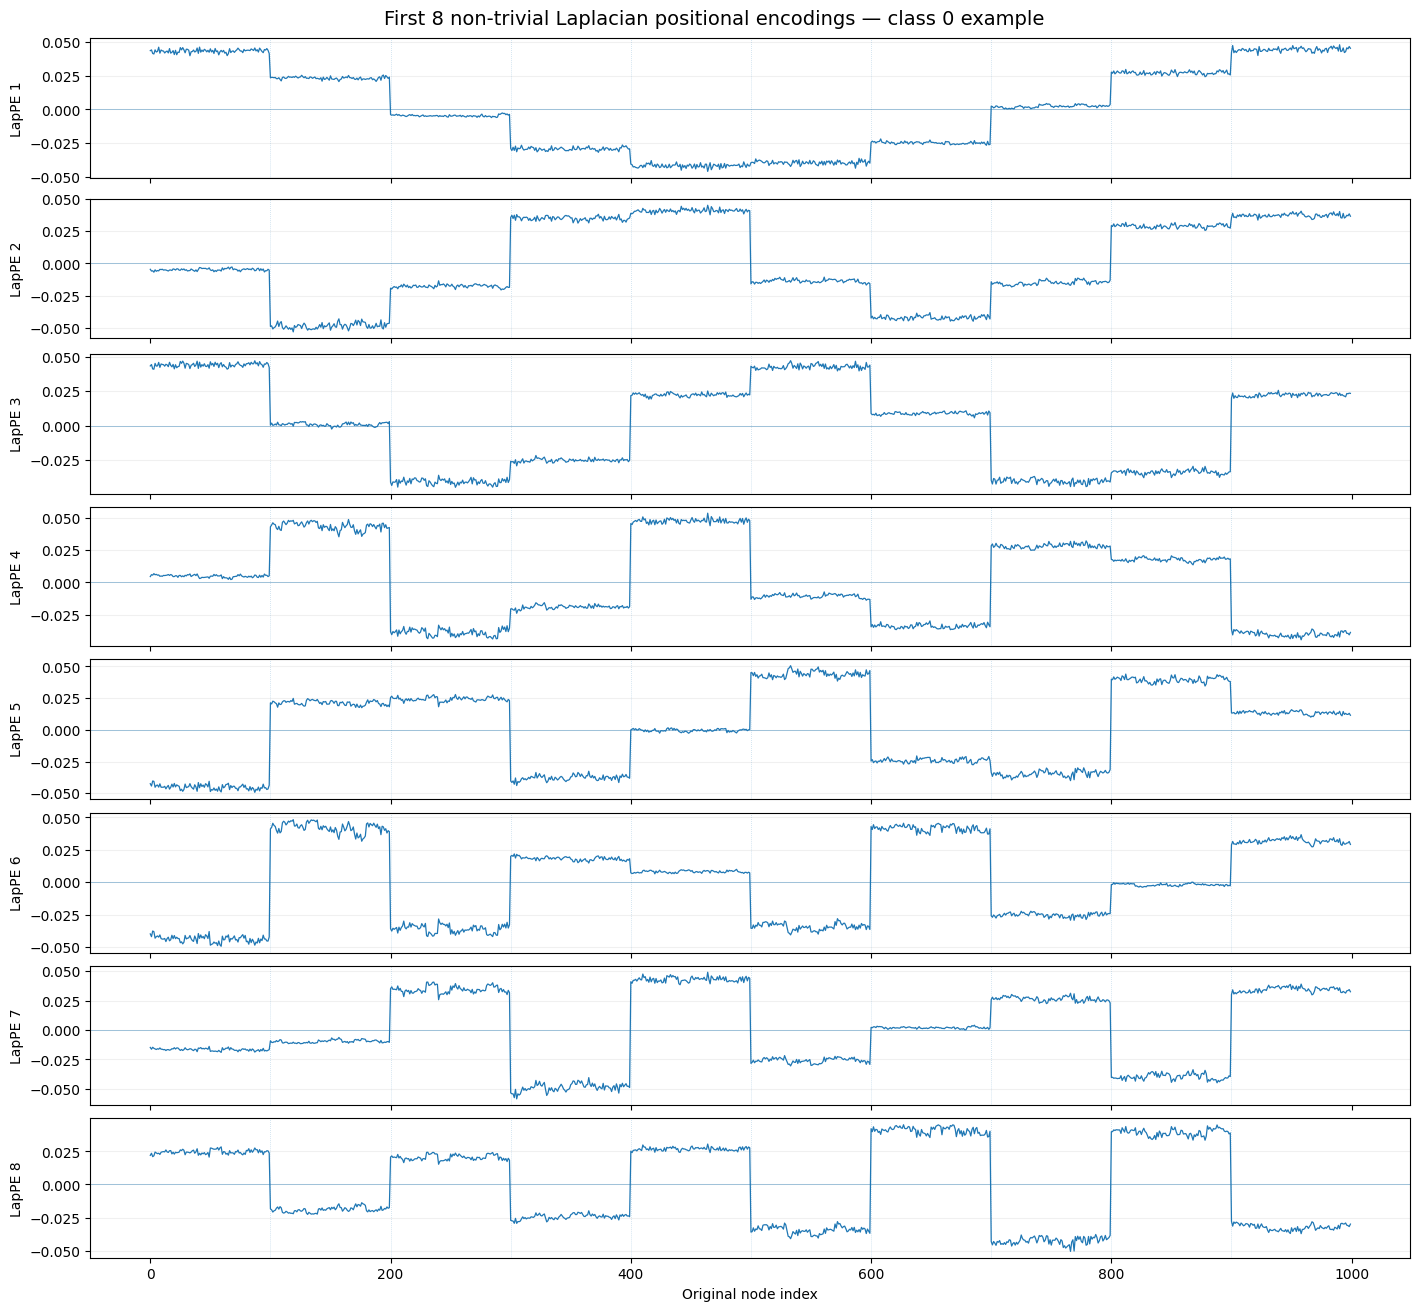

In [9]:
# Visualize the same 8 LapPE coordinates used by the Transformer models
lap_pe_demo = laplacian_eigenvectors(A_demo, POS_ENC_DIM).cpu().numpy()
print("LapPE matrix shape:", lap_pe_demo.shape)
node_index = np.arange(A_demo.shape[0])
fig, axes = plt.subplots(POS_ENC_DIM, 1, figsize=(14, 13), sharex=True, constrained_layout=True)
for k, ax in enumerate(axes):
    ax.plot(node_index, lap_pe_demo[:, k], linewidth=0.9)
    ax.axhline(0.0, linewidth=0.6, alpha=0.45)
    # Final coarse-community boundaries are derived from the hierarchy controls
    for boundary in range(TOP_COMMUNITY_SIZE, N_NODES, TOP_COMMUNITY_SIZE):
        ax.axvline(boundary, linestyle=":", linewidth=0.55, alpha=0.30)
    ax.set_ylabel(f"LapPE {k + 1}")
    ax.grid(axis="y", alpha=0.18)
axes[-1].set_xlabel("Original node index")
fig.suptitle( "First 8 non-trivial Laplacian positional encodings — class 0 example", fontsize=14, )
plt.show()


## Prepare train / test samples as sparse DGL graphs

Every sample stores only sparse graph topology plus dense node features (which are small):

- one DGL graph at the original resolution for the GCN and flat Graph Transformer,
- one sparse DGL local graph $D^{(\ell)}$ for every HEM transition,
- one sparse DGL final coarse graph,
- the HEM parent maps,
- original node feature `x`, LapPE, and the graph label.

The DGL graphs contain self-loops explicitly because both the GCN and Transformer include self-information. No dense adjacency tensors are packed anywhere.


In [10]:
DGL_IDTYPE = torch.int32

# Convert sparse SciPy topology to a sparse DGLGraph without densifying
def scipy_to_dgl_topology(W, add_self_loops=True):
    W = sparse_without_diagonal(W).tocoo()
    n = W.shape[0]
    src = W.row.astype(np.int32, copy=False)
    dst = W.col.astype(np.int32, copy=False)
    if add_self_loops:
        diagonal = np.arange(n, dtype=np.int32)
        src = np.concatenate([src, diagonal])
        dst = np.concatenate([dst, diagonal])
    return dgl.graph( ( torch.from_numpy(src), torch.from_numpy(dst), ), num_nodes=n, idtype=DGL_IDTYPE, )

# Generate one SBM graph, build its HEM hierarchy and LapPE features, and package everything for DGL training.
def prepare_sample(label, seed):
    A, x, y = make_hierarchical_sbm(label, seed)
    graphs, parents, local_graphs = hem_hierarchy(A)
    sizes = [g.shape[0] for g in graphs]
    if sizes != HIERARCHY_SIZES:
        raise RuntimeError( f"Unexpected hierarchy sizes: {sizes}; expected {HIERARCHY_SIZES}." )
    lap_pe = laplacian_eigenvectors(A, POS_ENC_DIM)
    # Convert the full graph at every hierarchy level to sparse DGL topology.
    # hierarchy_dgl_graphs contains A^(0), A^(1), ..., A^(L).
    hierarchy_dgl_graphs = tuple( scipy_to_dgl_topology(W) for W in graphs )
    # Local disconnected graphs D^(0), D^(1), ... are kept separately for
    # hierarchical local message passing.
    local_dgl_graphs = tuple( scipy_to_dgl_topology(D) for D in local_graphs )
    original_graph = hierarchy_dgl_graphs[0]
    final_graph = hierarchy_dgl_graphs[-1]
    return { "graph": original_graph, "hierarchy_graphs": hierarchy_dgl_graphs, "local_graphs": local_dgl_graphs, "final_graph": final_graph, "x": torch.tensor(x, dtype=torch.float32), "lap_pe": lap_pe, "y": int(y), "hierarchy_parents": [p.astype(np.int64) for p in parents], }


# Measure the total wall-clock time required to prepare the dataset.
start_time = time.perf_counter()

train_data, test_data = [], []
for label in range(N_CLASSES):
    class_graphs = [prepare_sample(label, seed) for seed in DATASET_SEEDS]
    train_data += class_graphs[:N_TRAIN_PER_CLASS]
    test_data += class_graphs[N_TRAIN_PER_CLASS:]

rng = np.random.default_rng(7)
rng.shuffle(train_data)
rng.shuffle(test_data)

elapsed_time = time.perf_counter() - start_time

print("train graphs:", len(train_data))
print("test graphs:", len(test_data))
print("test class counts:", np.bincount([s["y"] for s in test_data], minlength=N_CLASSES))
print("hierarchy sizes:", HIERARCHY_SIZES)
print(f"dataset preparation time: {elapsed_time:.2f} seconds")
print("first DGL graph:", train_data[0]["graph"])


train graphs: 400
test graphs: 40
test class counts: [10 10 10 10]
hierarchy sizes: [1000, 100, 10]
dataset preparation time: 162.51 seconds
first DGL graph: Graph(num_nodes=1000, num_edges=27426,
      ndata_schemes={}
      edata_schemes={})


In [11]:
# Batch original sparse DGL graphs and concatenate original node features
def collate_baseline_samples(samples):
    graph = dgl.batch([sample["graph"] for sample in samples])
    x = torch.cat([sample["x"] for sample in samples], dim=0)
    pe = torch.cat([sample["lap_pe"] for sample in samples], dim=0)
    y = torch.tensor([sample["y"] for sample in samples], dtype=torch.long)
    return graph, x, pe, y

# Batch every sparse hierarchy level and build global parent indices
def collate_hierarchical_samples(samples):
    local_graphs = tuple( dgl.batch([sample["local_graphs"][level] for sample in samples]) for level in range(HIERARCHY_LEVELS) )
    parent_maps = []
    for level in range(HIERARCHY_LEVELS):
        n_parent_per_graph = HIERARCHY_SIZES[level + 1]
        pieces = []
        for batch_id, sample in enumerate(samples):
            parent = torch.from_numpy(sample["hierarchy_parents"][level]).long()
            pieces.append(parent + batch_id * n_parent_per_graph)
        parent_maps.append(torch.cat(pieces, dim=0))
    original_x = torch.cat([sample["x"] for sample in samples], dim=0)
    original_lap_pe = torch.cat([sample["lap_pe"] for sample in samples], dim=0)
    final_graph = dgl.batch([sample["final_graph"] for sample in samples])
    y = torch.tensor([sample["y"] for sample in samples], dtype=torch.long)
    return ( local_graphs, tuple(parent_maps), original_x, original_lap_pe, final_graph, y, )


_demo_graph, _demo_x, _demo_pe, _demo_y = collate_baseline_samples(train_data[:2])
print("batched DGL baseline graph:", _demo_graph)
print("batched x:", tuple(_demo_x.shape))
print("batched LapPE:", tuple(_demo_pe.shape))


batched DGL baseline graph: Graph(num_nodes=2000, num_edges=54608,
      ndata_schemes={}
      edata_schemes={})
batched x: (2000, 1)
batched LapPE: (2000, 8)


## Model 1 — DGL GCN (topology only)

The GCN uses DGL's sparse `GraphConv` layers. The DGL graph contains the original binary topology plus one self-loop per node, so `GraphConv(..., norm="both")` applies symmetric degree normalization without using a dense adjacency matrix.

The model uses:
- input feature dimension: **1** (normalized binary degree),
- hidden dimension: **24**,
- GCN layers: **2**,
- graph readout: DGL mean pooling,
- four output classes.


In [12]:
class GCN(nn.Module):

    def __init__(self, hidden_dim=24):
        super().__init__()
        self.conv1 = GraphConv( 1, hidden_dim, norm="both", weight=True, bias=True, allow_zero_in_degree=True, )
        self.conv2 = GraphConv( hidden_dim, hidden_dim, norm="both", weight=True, bias=True, allow_zero_in_degree=True, )
        self.classifier = nn.Linear(hidden_dim, N_CLASSES)

    def forward(self, graph, x, pe=None):
        h = F.relu(self.conv1(graph, x))
        h = F.relu(self.conv2(graph, h))
        with graph.local_scope():
            graph.ndata["h_readout"] = h
            graph_embedding = dgl.mean_nodes(graph, "h_readout")
        return self.classifier(graph_embedding)


## Model 2 — Graph Transformer + LapPE


### Graph / sparse attention function

The flat Graph Transformer performs edge-sparse attention: attention is evaluated only on DGL edges (including self-loops), so it never forms a dense $N\times N$ attention matrix.

For each directed edge $j\to i$ and attention head, the score is

$$
s_{ij}=\frac{q_i^\top k_j}{\sqrt{d_h}},
$$

and DGL `edge_softmax(..., norm_by="dst")` normalizes over the incoming neighbors of node $i$:

$$
\alpha_{ij}
=
\frac{\exp(s_{ij})}
{\sum_{r\in\mathcal{N}(i)}\exp(s_{ir})}.
$$

The value vectors are then aggregated only along graph edges,

$$
z_i=\sum_{j\in\mathcal{N}(i)}\alpha_{ij}v_j.
$$

Thus each node attends only to itself and its graph neighbors.


### Initial node representation with LapPE

LapPE is computed once on the original weighted graph from the normalized Laplacian

$$
L=I-D^{-1/2}AD^{-1/2},
\qquad
Lu_k=\lambda_k u_k.
$$

Using the first non-trivial eigenvectors, the positional encoding of node $i$ is

$$
p_i=
\begin{bmatrix}
u_1(i) & \cdots & u_m(i)
\end{bmatrix},
\qquad m=\texttt{POS\_ENC\_DIM}=8.
$$

The degree feature $x_i$ and LapPE vector $p_i$ are projected to the same hidden space and added:

$$
h_i^{(0)}=W_xx_i+W_pp_i.
$$

During training, each LapPE coordinate may be multiplied by a random sign once per graph, reflecting the sign ambiguity of Laplacian eigenvectors.


For the training configuration used below, the model has:

- node feature dimension: **1** (normalized binary degree),
- LapPE dimension: **8**,
- hidden dimension: **48**,
- attention heads: **12** ($d_h=48/12=4$ per head),
- Transformer layers: **3** (= `N_HIERARCHIES`),
- graph readout: **DGL mean pooling**,
- output classes: **4**.

### Exercise 3 — Sparse graph attention

#### Question 3.1: Implement attention on directed DGL edges

For each edge $j\to i$, compute $q_i^\top k_j/\sqrt{d_h}$, normalize over
incoming edges at destination $i$, and aggregate the source value vectors.


In [13]:
# Flip each LapPE coordinate once per graph, not once per node
def random_sign_flip_batched(pe, batched_graph):
    batch_num_nodes = batched_graph.batch_num_nodes().long().to(pe.device)
    n_graphs = int(batch_num_nodes.numel())
    signs = 2 * torch.randint( 0, 2, (n_graphs, pe.shape[-1]), device=pe.device ).float() - 1.0
    node_signs = torch.repeat_interleave(signs, batch_num_nodes, dim=0)
    return pe * node_signs

# Multi-head Transformer attention evaluated only on DGL edges
class GraphAttentionLayer(nn.Module):
    def __init__(self, hidden_dim=48, num_heads=4):
        super().__init__()
        assert hidden_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads
        self.WQ = nn.Linear(hidden_dim, hidden_dim)
        self.WK = nn.Linear(hidden_dim, hidden_dim)
        self.WV = nn.Linear(hidden_dim, hidden_dim)
        self.WO = nn.Linear(hidden_dim, hidden_dim)
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.norm2 = nn.LayerNorm(hidden_dim)
        self.mlp = nn.Sequential( nn.Linear(hidden_dim, 2 * hidden_dim), nn.ReLU(), nn.Linear(2 * hidden_dim, hidden_dim), )
    def forward(self, graph, h):
        N, D = h.shape
        H, d = self.num_heads, self.head_dim
        q = self.WQ(h).view(N, H, d)
        k = self.WK(h).view(N, H, d)
        v = self.WV(h).view(N, H, d)
        with graph.local_scope():
            # Edge j -> i should use k_j^T q_i, matching dense q_i^T k_j.
            graph.ndata["q"] = q
            graph.ndata["k"] = k
            graph.ndata["v"] = v
            ###############################################
            # YOUR CODE STARTS HERE
            # YOUR CODE
            ###############################################
            graph.apply_edges(fn.u_dot_v("k", "q", "score"))
            score = graph.edata["score"] / math.sqrt(d)
            graph.edata["attn"] = edge_softmax( graph, score, norm_by="dst" )
            graph.update_all( fn.u_mul_e("v", "attn", "message"), fn.sum("message", "z"), )
            z = graph.ndata["z"].reshape(N, D)
            ###############################################
            # YOUR CODE ENDS HERE
            ###############################################
        # Preserve the layer-normalization placement of the attached notebook.
        h = h + self.WO(self.norm1(z))
        h = h + self.mlp(self.norm2(h))
        return h

# Define a flat graph Transformer that combines degree features with Laplacian positional encodings for graph classification
class GraphTransformer(nn.Module):
    def __init__(self, hidden_dim=48, num_heads=4, num_layers=3, pos_enc_dim=POS_ENC_DIM):
        super().__init__()
        self.input_embedding = nn.Linear(1, hidden_dim)
        self.pos_embedding = nn.Linear(pos_enc_dim, hidden_dim)
        self.layers = nn.ModuleList([ GraphAttentionLayer(hidden_dim, num_heads) for _ in range(num_layers) ])
        self.classifier = nn.Sequential( nn.LayerNorm(hidden_dim), nn.Linear(hidden_dim, N_CLASSES), )
    def forward(self, graph, x, pe):
        if self.training and RANDOMIZE_LAPPE_SIGNS:
            pe = random_sign_flip_batched(pe, graph)
        h = self.input_embedding(x) + self.pos_embedding(pe)
        for layer in self.layers:
            h = layer(graph, h)
        with graph.local_scope():
            graph.ndata["h_readout"] = h
            graph_embedding = dgl.mean_nodes(graph, "h_readout")
        return self.classifier(graph_embedding)


## Model 3 — Hierarchical Graph Transformer + LapPE

The Hierarchical Graph Transformer + LapPE combines spectral positional information with HEM-based graph coarsening. Instead of applying every Transformer layer to all original nodes, it alternates:

1. sparse Transformer attention within each HEM group,
2. mean-pooling of child embeddings to their parent nodes,
3. repetition at the next coarser resolution,
4. one final sparse Transformer stage on the coarsest graph.

This lets the receptive field grow across the hierarchy while keeping all message passing sparse.

### Sparse local Transformer attention

At hierarchy level $\ell$, attention is evaluated only on edges of the disconnected local HEM graph $D^{(\ell)}$. For an edge $j\to i$ and one attention head,

$$
s_{ij}^{(\ell)}
=
\frac{
(W_Q h_i^{(\ell)})^T
(W_K h_j^{(\ell)})
}
{\sqrt{d_h}},
$$

$$
\alpha_{ij}^{(\ell)}
=
\frac{\exp(s_{ij}^{(\ell)})}
{\sum_{r\in\mathcal{N}_{D^{(\ell)}}(i)}
\exp(s_{ir}^{(\ell)})},
$$

and the attention aggregation is

$$
z_i^{(\ell)}
=
\sum_{j\in\mathcal{N}_{D^{(\ell)}}(i)}
\alpha_{ij}^{(\ell)}\,W_V h_j^{(\ell)}.
$$

Because $D^{(\ell)}$ contains no edges between different HEM groups, one DGL attention pass over the full disconnected graph is equivalent to applying the same Transformer independently to every HEM component.

### Pooling from children to parents

Let $\pi_\ell(i)$ be the HEM parent of node $i$, and let

$$
C_r^{(\ell)}
=
\{i:\pi_\ell(i)=r\}
$$

be the children assigned to parent $r$. After local attention, child embeddings are mean-pooled:

$$
h_r^{(\ell+1)}
=
\frac{1}{\left|C_r^{(\ell)}\right|}
\sum_{i\in C_r^{(\ell)}}\hat{h}_i^{(\ell)},
$$

where $\hat{h}_i^{(\ell)}$ denotes the output of the local Transformer block.

The LapPE information is carried upward through the learned embeddings.

After all HEM transitions, one final sparse Transformer stage operates on the coarsest graph. The graph representation is the mean of the final node embeddings,

$$
h_G
=
\frac{1}{N_{\mathrm{final}}}
\sum_{i=1}^{N_{\mathrm{final}}}
h_i^{(\mathrm{final})},
$$

and the classifier maps $h_G$ to the four class logits.

For the training configuration used below, the model has:

- node feature dimension: **1** (normalized binary degree),
- LapPE dimension: **8**,
- hidden dimension: **48**,
- attention heads: **12** ($d_h=4$ per head),
- HEM coarsening transitions: **2** (`HIERARCHY_LEVELS`), giving $1000\to100\to10$ nodes,
- local Transformer layers: **1 per coarsening transition**,
- final coarse-graph Transformer layers: **1**,
- graph readout: **DGL mean pooling**,
- output classes: **4**.

No dense local adjacency blocks, child masks, or final dense attention matrices are created.

### Exercise 4 — Hierarchical pooling and propagation

#### Question 4.1: Mean-pool child embeddings to parents

Use `index_add_` to accumulate child embeddings and child counts for each
parent, then divide by the clamped counts.

#### Question 4.2: Propagate through the hierarchy

At each HEM transition, determine the number of parent nodes and apply the
corresponding local Graph Transformer followed by parent pooling.


In [14]:
# Mean-pool child node embeddings to parents with O(ND) index_add
def mean_pool_by_parent(h, parent_index, n_parent):
    parent_index = parent_index.to(h.device)
    out = h.new_zeros((n_parent, h.shape[-1]))
    ###############################################
    # YOUR CODE STARTS HERE
    # YOUR CODE
    ###############################################
    out.index_add_(0, parent_index, h)
    counts = h.new_zeros((n_parent, 1))
    counts.index_add_( 0, parent_index, torch.ones((h.shape[0], 1), device=h.device, dtype=h.dtype), )
    return out / counts.clamp(min=1.0)
    ###############################################
    # YOUR CODE ENDS HERE
    ###############################################

# Sparse DGL GT on a disconnected union of HEM-local components, then pool
class IndependentSubgraphGT(nn.Module):
    def __init__(self, hidden_dim=48, num_heads=4, num_layers=1):
        super().__init__()
        self.layers = nn.ModuleList([ GraphAttentionLayer(hidden_dim, num_heads) for _ in range(num_layers) ])
    def forward(self, local_graph, h_previous, parent_index, n_parent):
        h = h_previous
        for layer in self.layers:
            h = layer(local_graph, h)
        return mean_pool_by_parent(h, parent_index, n_parent)

# Define a hierarchical graph Transformer that alternates local HEM-group attention, parent pooling, and final coarse-graph attention.
class HierarchicalGraphTransformer(nn.Module):
    def __init__(self, pos_enc_dim=POS_ENC_DIM, hidden_dim=48, num_heads=4, n_hierarchy_levels=HIERARCHY_LEVELS, local_layers=1, final_layers=1):
        super().__init__()
        self.input_embedding = nn.Linear(1, hidden_dim)
        self.original_lap_projection = nn.Linear(pos_enc_dim, hidden_dim)
        self.local_gts = nn.ModuleList([ IndependentSubgraphGT(hidden_dim, num_heads, local_layers) for _ in range(n_hierarchy_levels) ])
        self.final_gt_layers = nn.ModuleList([ GraphAttentionLayer(hidden_dim, num_heads) for _ in range(final_layers) ])
        self.classifier = nn.Sequential( nn.LayerNorm(hidden_dim), nn.Linear(hidden_dim, N_CLASSES), )
    def forward( self, local_graphs, parent_maps, original_x, original_lap_pe, final_graph, ):
        if len(local_graphs) != len(self.local_gts):
            raise ValueError( f"Expected {len(self.local_gts)} local graphs, got {len(local_graphs)}." )
        if self.training and RANDOMIZE_LAPPE_SIGNS:
            original_lap_pe = random_sign_flip_batched( original_lap_pe, local_graphs[0] )
        h = ( self.input_embedding(original_x) + self.original_lap_projection(original_lap_pe) )
        for level, (local_gt, local_graph, parent_index) in enumerate(zip( self.local_gts, local_graphs, parent_maps )):
            ###############################################
            # YOUR CODE STARTS HERE
            # YOUR CODE
            ###############################################
            if level + 1 < len(local_graphs):
                n_parent = local_graphs[level + 1].num_nodes()
            else:
                n_parent = final_graph.num_nodes()
            h = local_gt(local_graph, h, parent_index, n_parent)
            ###############################################
            # YOUR CODE ENDS HERE
            ###############################################
        for layer in self.final_gt_layers:
            h = layer(final_graph, h)
        with final_graph.local_scope():
            final_graph.ndata["h_readout"] = h
            graph_embedding = dgl.mean_nodes(final_graph, "h_readout")
        return self.classifier(graph_embedding)


## Sparse mini-batching and training

DGL `batch` forms a disjoint union of sparse graphs, so mini-batching does not create a dense block adjacency matrix.

All three models use AdamW with a constant learning rate.


In [15]:
# Provide shuffled or sequential mini-batch index lists
def batch_indices(n, batch_size, shuffle=True):
    idx = torch.randperm(n) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        yield idx[start:start + batch_size].tolist()

# Train a baseline graph model with AdamW and cross-entropy loss
def train_baseline(model, epochs=12, batch_size=1, lr=1e-3):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    n = len(train_data)
    model_name = model.__class__.__name__
    model.train()
    for epoch in range(epochs):
        epoch_loss_sum = 0.0
        epoch_examples = 0
        for idx in batch_indices(n, batch_size, shuffle=True):
            samples = [train_data[i] for i in idx]
            graph, x, pe, y = collate_baseline_samples(samples)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(graph, x, pe), y)
            loss.backward()
            optimizer.step()
            batch_examples = len(samples)
            epoch_loss_sum += loss.detach().item() * batch_examples
            epoch_examples += batch_examples
        mean_epoch_loss = epoch_loss_sum / max(epoch_examples, 1)
        if not (epoch + 1) % 10 or epoch == 0 or epoch + 1 == epochs:
            print( f"epoch {epoch + 1:03d} | {model_name} " f"training loss: {mean_epoch_loss:.6f}" )
    return model

# Train the hierarchical graph Transformer with AdamW, cross-entropy loss and gradient clipping
def train_hierarchical_gt(model, epochs=12, batch_size=1, lr=1e-3):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    n = len(train_data)
    model.train()
    for epoch in range(epochs):
        epoch_loss_sum = 0.0
        epoch_examples = 0
        for idx in batch_indices(n, batch_size, shuffle=True):
            samples = [train_data[i] for i in idx]
            batch = collate_hierarchical_samples(samples)
            *model_inputs, y = batch
            optimizer.zero_grad()
            loss = F.cross_entropy(model(*model_inputs), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_examples = len(samples)
            epoch_loss_sum += loss.detach().item() * batch_examples
            epoch_examples += batch_examples
        mean_epoch_loss = epoch_loss_sum / max(epoch_examples, 1)
        if not (epoch + 1) % 10 or epoch == 0 or epoch + 1 == epochs:
            print( f"epoch {epoch + 1:03d} | HierarchicalGraphTransformer " f"training loss: {mean_epoch_loss:.6f}" )
    return model

# Evaluate classification accuracy for a baseline model without tracking gradients
@torch.no_grad()
def baseline_accuracy(model, data, batch_size=1):
    model.eval()
    correct = 0
    total = 0
    for idx in batch_indices(len(data), batch_size, shuffle=False):
        samples = [data[i] for i in idx]
        graph, x, pe, y = collate_baseline_samples(samples)
        pred = model(graph, x, pe).argmax(dim=1)
        correct += int((pred == y).sum())
        total += len(samples)
    return correct / max(total, 1)

# Evaluate classification accuracy for the hierarchical graph Transformer without tracking gradients
@torch.no_grad()
def hierarchical_gt_accuracy(model, data, batch_size=1):
    model.eval()
    correct = 0
    total = 0
    for idx in batch_indices(len(data), batch_size, shuffle=False):
        samples = [data[i] for i in idx]
        batch = collate_hierarchical_samples(samples)
        *model_inputs, y = batch
        pred = model(*model_inputs).argmax(dim=1)
        correct += int((pred == y).sum())
        total += len(samples)
    return correct / max(total, 1)

# Count the model parameters that are updated during training
def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


## Print HEM statistics for each hierarchy level

In [16]:
def print_mean_graph_size_by_class(data, split_name):
    print(f"\n{split_name} mean graph / HEM statistics by hierarchy level:")
    print("  level | mean nodes | mean edges | sparsity (%) | mean HEM clusters | mean nodes / cluster")
    for level in range(N_HIERARCHIES):
        class_node_means = []
        class_edge_means = []
        class_sparsity_means = []
        class_cluster_means = []
        class_nodes_per_cluster_means = []
        for class_id in range(N_CLASSES):
            class_samples = [sample for sample in data if int(sample["y"]) == class_id]
            if not class_samples:
                continue
            node_counts = np.array([sample["hierarchy_graphs"][level].num_nodes() for sample in class_samples], dtype=np.float64)
            edge_counts = np.array([sample["hierarchy_graphs"][level].num_edges() for sample in class_samples], dtype=np.float64)
            sparsity_percentages = (1.0 - edge_counts / (node_counts ** 2)) * 100.0
            class_node_means.append(node_counts.mean())
            class_edge_means.append(edge_counts.mean())
            class_sparsity_means.append(sparsity_percentages.mean())
            if level < HIERARCHY_LEVELS:
                cluster_counts = []
                nodes_per_cluster = []
                for sample in class_samples:
                    parent = sample["hierarchy_parents"][level]
                    counts = np.bincount(parent)
                    cluster_counts.append(len(counts))
                    nodes_per_cluster.append(counts.mean())
                class_cluster_means.append(np.mean(cluster_counts))
                class_nodes_per_cluster_means.append(np.mean(nodes_per_cluster))
        if not class_node_means:
            print(f"  {level:5d} | {'n/a':>10} | {'n/a':>10} | {'n/a':>12} | {'n/a':>17} | {'n/a':>20}")
            continue
        mean_nodes = np.mean(class_node_means)
        mean_edges = np.mean(class_edge_means)
        mean_sparsity = np.mean(class_sparsity_means)
        if level < HIERARCHY_LEVELS:
            mean_clusters = np.mean(class_cluster_means)
            mean_nodes_per_cluster = np.mean(class_nodes_per_cluster_means)
            cluster_text = f"{mean_clusters:17.2f}"
            nodes_per_cluster_text = f"{mean_nodes_per_cluster:20.2f}"
        else:
            cluster_text = f"{'n/a':>17}"
            nodes_per_cluster_text = f"{'n/a':>20}"
        print(f"  {level:5d} | {mean_nodes:10.2f} | {mean_edges:10.2f} | {mean_sparsity:12.4f} | {cluster_text} | {nodes_per_cluster_text}")

print_mean_graph_size_by_class(train_data, "Train")
# print_mean_graph_size_by_class(test_data, "Test")
print('')



Train mean graph / HEM statistics by hierarchy level:
  level | mean nodes | mean edges | sparsity (%) | mean HEM clusters | mean nodes / cluster
      0 |    1000.00 |   23821.20 |      97.6179 |            100.00 |                10.00
      1 |     100.00 |    3933.49 |      60.6651 |             10.00 |                10.00
      2 |      10.00 |      92.10 |       7.9000 |               n/a |                  n/a



## Train the three sparse DGL models and compare wall-clock time

All three models use the same constant `LEARNING_RATE`. `BATCH_SIZE` controls the number of whole sparse graphs batched by DGL.


In [17]:
EPOCHS = 100
# EPOCHS = 2 # debug
BATCH_SIZE = 10
LEARNING_RATE = 0.0003

results = {}
parameter_counts = {}
training_times = {}

# Train and evaluate the topology-only GCN baseline
set_seed(0)
gcn = GCN()
start = time.perf_counter()
gcn = train_baseline( gcn, EPOCHS, BATCH_SIZE, LEARNING_RATE )
training_times["GCN (topology only)"] = time.perf_counter() - start
results["GCN (topology only)"] = baseline_accuracy(gcn, test_data, batch_size=BATCH_SIZE)
parameter_counts["GCN (topology only)"] = count_trainable_parameters(gcn)
print("GCN (topology only):")
print("  test accuracy:", results["GCN (topology only)"])
print( f"  training time: {training_times['GCN (topology only)']:.2f} s " f"({training_times['GCN (topology only)'] / 60:.2f} min)" )
print('')

# Train and evaluate the flat Graph Transformer with LapPE
set_seed(0)
gt = GraphTransformer( hidden_dim=48, num_heads=12, num_layers=N_HIERARCHIES, pos_enc_dim=POS_ENC_DIM, )
start = time.perf_counter()
gt = train_baseline( gt, EPOCHS, BATCH_SIZE, LEARNING_RATE )
training_times["Graph Transformer + LapPE"] = time.perf_counter() - start
results["Graph Transformer + LapPE"] = baseline_accuracy(gt, test_data, batch_size=BATCH_SIZE)
parameter_counts["Graph Transformer + LapPE"] = count_trainable_parameters(gt)
print("\nGraph Transformer + LapPE:")
print("  test accuracy:", results["Graph Transformer + LapPE"])
print( f"  training time: {training_times['Graph Transformer + LapPE']:.2f} s " f"({training_times['Graph Transformer + LapPE'] / 60:.2f} min)" )
print('')

# Train and evaluate the hierarchical Graph Transformer with LapPE
set_seed(0)
hierarchical_gt = HierarchicalGraphTransformer( pos_enc_dim=POS_ENC_DIM, hidden_dim=48, num_heads=12, n_hierarchy_levels=HIERARCHY_LEVELS)
start = time.perf_counter()
hierarchical_gt = train_hierarchical_gt( hierarchical_gt, EPOCHS, BATCH_SIZE, LEARNING_RATE )
training_times["Hierarchical GT + LapPE"] = time.perf_counter() - start
results["Hierarchical GT + LapPE"] = hierarchical_gt_accuracy( hierarchical_gt, test_data, batch_size=BATCH_SIZE )
parameter_counts["Hierarchical GT + LapPE"] = count_trainable_parameters(hierarchical_gt)
print("\nHierarchical GT + LapPE:")
print("  test accuracy:", results["Hierarchical GT + LapPE"])
print( f"  training time: {training_times['Hierarchical GT + LapPE']:.2f} s " f"({training_times['Hierarchical GT + LapPE'] / 60:.2f} min)" )
print('')

# Summarize model accuracy, size, runtime, and speed relative to the flat Graph Transformer
comparison_table = pd.DataFrame({ "model": list(results.keys()), "test_accuracy": [results[k] for k in results], "trainable_parameters": [parameter_counts[k] for k in results], "training_time_seconds": [training_times[k] for k in results], "training_time_minutes": [training_times[k] / 60 for k in results], })
if "Graph Transformer + LapPE" in training_times:
    comparison_table["speed_vs_flat_GT"] = ( training_times["Graph Transformer + LapPE"] / comparison_table["training_time_seconds"] )
else:
    comparison_table["speed_vs_flat_GT"] = np.nan
comparison_table


epoch 001 | GCN training loss: 1.391818
epoch 010 | GCN training loss: 1.388758
epoch 020 | GCN training loss: 1.386792
epoch 030 | GCN training loss: 1.385701
epoch 040 | GCN training loss: 1.384475
epoch 050 | GCN training loss: 1.383296
epoch 060 | GCN training loss: 1.381153
epoch 070 | GCN training loss: 1.378148
epoch 080 | GCN training loss: 1.374021
epoch 090 | GCN training loss: 1.369297
epoch 100 | GCN training loss: 1.362686
GCN (topology only):
  test accuracy: 0.5
  training time: 45.31 s (0.76 min)

epoch 001 | GraphTransformer training loss: 1.421821
epoch 010 | GraphTransformer training loss: 1.395917
epoch 020 | GraphTransformer training loss: 1.357712
epoch 030 | GraphTransformer training loss: 0.047638
epoch 040 | GraphTransformer training loss: 0.023193
epoch 050 | GraphTransformer training loss: 0.093055
epoch 060 | GraphTransformer training loss: 0.003805
epoch 070 | GraphTransformer training loss: 0.003005
epoch 080 | GraphTransformer training loss: 0.003770
epoc

,model,test_accuracy,trainable_parameters,training_time_seconds,training_time_minutes,speed_vs_flat_GT
0,GCN (topology only),0.5,748,45.313693,0.755228,50.277834
1,Graph Transformer + LapPE,1.0,57700,2278.274350,37.971239,1.000000
2,Hierarchical GT + LapPE,0.9,57700,438.642234,7.310704,5.193924
